## Objectif de cette analyse

L’objectif de cette analyse est de comprendre la répartition géographique des niveaux de vie et d’identifier les disparités socio-économiques entre territoires. À partir du revenu médian, du taux de pauvreté et des indices d’inégalités on voudrait être capable de :
- Mesurer les contrastes régionaux entre zones aisées et zones défavorisées

- Analyser la structure du revenu (part des salaires, retraites, aides sociales) selon les départements

- Observer le lien entre pauvreté et inégalités

In [4]:
# install necessary packages
install.packages("readxl")
install.packages("dplyr")
install.packages("tidyr")
install.packages("ggplot2")
install.packages("maps")
install.packages("mapproj")
install.packages("FactoMineR")
install.packages("factoextra")
install.packages("gplots")
install.packages("corrplot")
install.packages("ellipse")
install.packages("car")
install.packages("lmtest")
install.packages("writexl")

# Load necessary packages
library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(maps)
library(mapproj)
library(FactoMineR)
library(factoextra)
library(gplots)
library(corrplot)
library(ellipse)
library(car)
library(lmtest)
library(writexl)



# Plotting options
options(repr.plot.width = 14, repr.plot.height = 8)

also installing the dependency ‘cpp11’





The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages are in
	/var/folders/6t/l3cgh06n1rj2wpckspwwyc3m0000gn/T//RtmpiB3t6I/downloaded_packages

The downloaded binary packages 

## Présentation du jeu de données

Le jeu de données que nous analisions provient de la base FILOSOFI 2018 (Fichier Localisé Social et Fiscal) publiée par l’INSEE. 
Cette base combine des données fiscales anonymisées issues de la Direction Générale des Finances Publiques (DGFiP) avec des données démographiques de l’INSEE.

In [6]:
# Read the data from the Excel file
data <- read_excel("datasets.xlsx", sheet = 1)

# Convert the data to a data frame
data <- as.data.frame(data)

dim(data)
names(data)

[1] 12395    30

[1] "IRIS"                                                 
 [2] "Libellé de l'IRIS"                                    
 [3] "Commune ou ARM"                                       
 [4] "Libellé commune ou ARM"                               
 [5] "Département"                                          
 [6] "Libellé département"                                  
 [7] "Part des ménages fiscaux imposés (%)"                 
 [8] "Taux de bas revenus déclarés au seuil de 60 % (%)"    
 [9] "1er quartile (€)"                                     
[10] "Médiane (€)"                                          
[11] "3e quartile (€)"                                      
[12] "Écart inter-quartile rapporté à la médiane"           
[13] "1er décile (€)"                                       
[14] "2e décile (€)"                                        
[15] "3e décile (€)"                                        
[16] "4e décile (€)"                                        
[17] "6e décile (€)"                                        
[18] "7e décile (€)"                                        
[19] "8e décile (€)"                                        
[20] "9e décile (€)"                                        
[21] "Rapport interdécile D9/D1"                            
[22] "S80/S20"                                              
[23] "Indice de Gini"                                       
[24] "Part des revenus d’activité (%)"                      
[25] "dont part des salaires et traitements (%)"            
[26] "dont part des indemnités de chômage (%)"              
[27] "dont part des revenus des activités non salariées (%)"
[28] "Part des pensions, retraites et rentes (%)"           
[29] "Part des autres revenus (%)"                          
[30] "Note de précaution (voir onglet seuils)"

On renomme les colonnes avec des noms courts. Ce sont les codes officiels de l'INSEE :

| Code | Signification |
|---|---|
| PIMP | Part des ménages fiscaux imposés (%) |
| TP60 | Taux de bas revenus au seuil de 60 % (%), notre indicateur de pauvreté |
| Q1, MED, Q3 | 1er quartile, médiane, 3e quartile du revenu par UC (€) |
| D1 … D9 | Déciles du revenu par UC (€) |
| EQ | Écart interquartile / médiane |
| RD | Rapport interdécile D9/D1 |
| S80S20 | Ratio S80/S20 |
| GINI | Indice de Gini |
| PACT | Part des revenus d'activité (%) = PTSA + PCHO + PBEN |
| PTSA | dont salaires et traitements (%) |
| PCHO | dont indemnités de chômage (%) |
| PBEN | dont revenus des activités non salariées (%) |
| PPEN | Part des pensions, retraites et rentes (%) |
| PAUT | Part des autres revenus, surtout du patrimoine (%) |
| NOTE | Note de précaution de l'INSEE |

In [9]:
# Rename the columns
rename_columns <- data
names(rename_columns) <- c("IRIS", "LIBIRIS", "COM", "LIBCOM", "DEP", "LIBDEP", "PIMP", "TP60", "Q1", "MED", "Q3", "EQ", "D1", "D2", "D3", "D4", "D6", "D7", "D8", "D9", "RD", "S80S20", "GINI", "PACT", "PTSA", "PCHO", "PBEN", "PPEN", "PAUT", "NOTE")

# Check the structure and first few rows of the renamed data frame
str(rename_columns)
head(rename_columns)

'data.frame':	12395 obs. of  30 variables:
 $ IRIS   : chr  "010040101" "010040102" "010040201" "010040202" ...
 $ LIBIRIS: chr  "Les Perouses-Triangle d'Activité" "Longeray-Gare" "Centre-Saint-Germain-Vareilles" "Tiret-Les Allymes" ...
 $ COM    : chr  "01004" "01004" "01004" "01004" ...
 $ LIBCOM : chr  "Ambérieu-en-Bugey" "Ambérieu-en-Bugey" "Ambérieu-en-Bugey" "Ambérieu-en-Bugey" ...
 $ DEP    : chr  "01" "01" "01" "01" ...
 $ LIBDEP : chr  "Ain" "Ain" "Ain" "Ain" ...
 $ PIMP   : num  45.4 39.3 43.7 61.1 41.9 46.7 48.6 39.2 36.7 54.5 ...
 $ TP60   : num  31 39.4 28.8 14.6 25.9 21.2 20.6 34.5 29.9 11.4 ...
 $ Q1     : num  11150 8890 11830 17180 12660 ...
 $ MED    : num  18540 16180 18870 24780 19590 ...
 $ Q3     : num  25900 23290 26560 33280 28730 ...
 $ EQ     : num  0.8 0.89 0.78 0.65 0.82 0.86 0.84 0.91 0.89 0.75 ...
 $ D1     : num  5500 3800 6770 10380 6620 ...
 $ D2     : num  9490 7690 9990 15570 10530 ...
 $ D3     : num  12830 10230 13210 19020 13900 ...
 $ D4     : num

,IRIS,LIBIRIS,COM,LIBCOM,DEP,LIBDEP,PIMP,TP60,Q1,MED,⋯,RD,S80S20,GINI,PACT,PTSA,PCHO,PBEN,PPEN,PAUT,NOTE
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,010040101,Les Perouses-Triangle d'Activité,01004,Ambérieu-en-Bugey,01,Ain,45.4,31.0,11150,18540,⋯,6.2,7.2,0.332,68.9,63.2,3.1,2.6,27.3,3.8,0
2,010040102,Longeray-Gare,01004,Ambérieu-en-Bugey,01,Ain,39.3,39.4,8890,16180,⋯,8.3,9.8,0.366,69.6,62.9,4.5,2.2,26.9,3.5,0
3,010040201,Centre-Saint-Germain-Vareilles,01004,Ambérieu-en-Bugey,01,Ain,43.7,28.8,11830,18870,⋯,5.2,7.4,0.347,67.7,60.6,3.1,4.0,28.3,4.0,0
4,010040202,Tiret-Les Allymes,01004,Ambérieu-en-Bugey,01,Ain,61.1,14.6,17180,24780,⋯,4.3,7.3,0.387,62.7,57.5,2.1,3.1,21.2,16.1,0
5,010330102,Centre Ville,01033,Valserhône,01,Ain,41.9,25.9,12660,19590,⋯,6.2,8.6,0.365,70.2,63.8,4.1,2.3,25.8,4.0,0
6,010330103,Lancrans-Coupy-Vanchy,01033,Valserhône,01,Ain,46.7,21.2,14700,22970,⋯,6.3,7.4,0.358,75.8,70.4,3.5,1.9,19.4,4.8,0


## Préparation des données

- On supprime les IRIS dont la note de précaution vaut 5 car ce sont les données jugées anormales par l'INSEE.
- On compte les valeurs manquantes, qui viennent du secret statistique.
- On ajoute la région, une variable qualitative.

In [12]:
# Remove rows with NOTE equal to 5
table(rename_columns$NOTE)
rename_columns <- rename_columns[rename_columns$NOTE != 5, ]

# Check the dimensions of the data frame after removing rows
dim(rename_columns)

# Missing values per variable
colSums(is.na(rename_columns))


    0     1 
12262   132 

[1] 12394    30

IRIS LIBIRIS     COM  LIBCOM     DEP  LIBDEP    PIMP    TP60      Q1     MED 
      0       0       0       0       0       0    1004    1796       0       0 
     Q3      EQ      D1      D2      D3      D4      D6      D7      D8      D9 
      0       0       0       0       0       0       0       0       0       0 
     RD  S80S20    GINI    PACT    PTSA    PCHO    PBEN    PPEN    PAUT    NOTE 
    654      39       0       0     440     440     440       0       0       0

In [14]:
# Region of each department
rename_columns$REGION <- NA
rename_columns$REGION[rename_columns$DEP %in% c("01","03","07","15","26","38","42","43","63","69","73","74")] <- "Auvergne-Rhone-Alpes"
rename_columns$REGION[rename_columns$DEP %in% c("21","25","39","58","70","71","89","90")]                     <- "Bourgogne-Franche-Comte"
rename_columns$REGION[rename_columns$DEP %in% c("22","29","35","56")]                                         <- "Bretagne"
rename_columns$REGION[rename_columns$DEP %in% c("18","28","36","37","41","45")]                               <- "Centre-Val de Loire"
rename_columns$REGION[rename_columns$DEP %in% c("2A","2B")]                                                   <- "Corse"
rename_columns$REGION[rename_columns$DEP %in% c("08","10","51","52","54","55","57","67","68","88")]           <- "Grand Est"
rename_columns$REGION[rename_columns$DEP %in% c("02","59","60","62","80")]                                    <- "Hauts-de-France"
rename_columns$REGION[rename_columns$DEP %in% c("75","77","78","91","92","93","94","95")]                     <- "Ile-de-France"
rename_columns$REGION[rename_columns$DEP %in% c("14","27","50","61","76")]                                    <- "Normandie"
rename_columns$REGION[rename_columns$DEP %in% c("16","17","19","23","24","33","40","47","64","79","86","87")] <- "Nouvelle-Aquitaine"
rename_columns$REGION[rename_columns$DEP %in% c("09","11","12","30","31","32","34","46","48","65","66","81","82")] <- "Occitanie"
rename_columns$REGION[rename_columns$DEP %in% c("44","49","53","72","85")]                                    <- "Pays de la Loire"
rename_columns$REGION[rename_columns$DEP %in% c("04","05","06","13","83","84")]                               <- "PACA"
rename_columns$REGION[rename_columns$DEP %in% c("972","974")]                                                 <- "DOM"
rename_columns$REGION <- as.factor(rename_columns$REGION)
table(rename_columns$REGION, useNA = "ifany")


   Auvergne-Rhone-Alpes Bourgogne-Franche-Comte                Bretagne 
                   1167                     329                     415 
    Centre-Val de Loire                   Corse                     DOM 
                    375                      43                     362 
              Grand Est         Hauts-de-France           Ile-de-France 
                    802                    1039                    3850 
              Normandie      Nouvelle-Aquitaine               Occitanie 
                    481                     753                     816 
                   PACA        Pays de la Loire 
                   1364                     598 

## Tableau par département
Les données sont au niveau du quartier. Pour comparer les départements, on calcule pour chacun la moyenne de ses IRIS. On obtient un tableau d'une ligne par département.

Pour D9/D1 et S80/S20, on prend la médiane et non la moyenne. Ces rapports deviennent énormes dans les quartiers où le 1er décile est proche de 0 €, et la moyenne n'aurait plus de sens.

In [ ]:
# Create a new data frame 'd' with selected columns
vars <- c("MED","Q1","Q3","D1","D2","D3","D4","D6","D7","D8","D9", "TP60","PIMP","GINI","EQ","PACT","PTSA","PCHO","PBEN","PPEN","PAUT")

# Aggregate the data by department and region, calculating the mean for selected variables
dep <- aggregate(rename_columns[, vars], by = list(DEP = rename_columns$DEP, LIBDEP = rename_columns$LIBDEP, REGION = rename_columns$REGION), FUN = mean, na.rm = TRUE)

# Calculate the median of RD and S80S20 by department
dep_ratio <- aggregate(rename_columns[, c("RD", "S80S20")], by = list(DEP = rename_columns$DEP), FUN = median, na.rm = TRUE)

# Merge the median ratios back into the department-level data frame
dep <- merge(dep, dep_ratio, by = "DEP")

# Number of IRIS per department
dep$n_iris <- as.vector(table(rename_columns$DEP)[dep$DEP])
rownames(dep) <- dep$LIBDEP
dim(dep)
head(dep)

# Metropolitan France only (used for maps and models)
dep_m <- dep[dep$REGION != "DOM", ]
dep_m$REGION <- droplevels(dep_m$REGION)
dim(dep_m)

[1] 98 27

,DEP,LIBDEP,REGION,MED,Q1,Q3,D1,D2,D3,D4,⋯,EQ,PACT,PTSA,PCHO,PBEN,PPEN,PAUT,RD,S80S20,n_iris
,<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Ain,01,Ain,Auvergne-Rhone-Alpes,19777.07,12268.293,28694.15,6202.683,10578.049,13850.00,16902.68,⋯,0.8390244,67.26585,61.00250,3.682500,2.685000,28.17317,4.560976,6.7,8.6,41
Aisne,02,Aisne,Hauts-de-France,16253.73,9220.448,24029.70,3440.597,7523.881,10758.36,13586.27,⋯,0.9761194,62.67910,55.11356,3.838983,4.494915,33.60597,3.714925,10.2,12.8,67
Allier,03,Allier,Auvergne-Rhone-Alpes,18615.11,11429.333,26237.33,4769.111,9611.778,13053.78,15906.67,⋯,0.8228889,55.59333,48.34444,3.008889,4.240000,40.34667,4.060000,7.8,9.8,45
Alpes-de-Haute-Provence,04,Alpes-de-Haute-Provence,PACA,19421.76,12282.941,27827.06,6168.824,10535.882,13817.06,16571.18,⋯,0.8429412,55.14706,47.61176,3.158824,4.376471,34.15294,10.700000,5.6,8.2,17
Hautes-Alpes,05,Hautes-Alpes,PACA,20479.05,13727.619,28201.90,8103.333,12083.810,15210.48,17931.90,⋯,0.7176190,59.69524,51.20952,3.080952,5.404762,34.28571,6.019048,4.4,6.2,21
Alpes-Maritimes,06,Alpes-Maritimes,PACA,21873.32,14001.677,31917.75,7629.880,12193.713,15663.77,18783.02,⋯,0.8350000,64.15299,55.39880,3.391265,5.321988,28.35329,7.493713,5.9,7.9,334


[1] 96 27

## Description, résumé statistique et visualisation

In [17]:
summary(rename_columns[, c("MED","TP60","GINI","RD","PTSA","PPEN")])

      MED             TP60            GINI              RD        
 Min.   : 2280   Min.   : 5.00   Min.   :0.1830   Min.   :   2.3  
 1st Qu.:16402   1st Qu.:16.70   1st Qu.:0.3280   1st Qu.:   4.8  
 Median :20860   Median :25.15   Median :0.3660   Median :   6.4  
 Mean   :21746   Mean   :29.27   Mean   :0.3735   Mean   :  18.5  
 3rd Qu.:25480   3rd Qu.:38.60   3rd Qu.:0.4110   3rd Qu.:   9.5  
 Max.   :73040   Max.   :90.00   Max.   :0.8050   Max.   :5140.2  
                 NA's   :1796                     NA's   :654     
      PTSA            PPEN      
 Min.   :17.90   Min.   :-0.40  
 1st Qu.:55.00   1st Qu.:19.40  
 Median :61.80   Median :25.20  
 Mean   :61.29   Mean   :25.92  
 3rd Qu.:68.30   3rd Qu.:31.80  
 Max.   :96.50   Max.   :65.90  
 NA's   :440                    

In [19]:
# Same table as in visualization_state.r, exported to Excel for the report
tem <- rename_columns[, c("MED","TP60","PIMP","D1","D9","RD","S80S20","GINI","PTSA","PCHO","PBEN","PPEN","PAUT")]

# Summary statistics
summary_stats <- data.frame(
  Min. = round(apply(tem, 2, min, na.rm = TRUE), 3),
  `1st Qu.` = round(apply(tem, 2, quantile, probs = 0.25, na.rm = TRUE), 3),
  Median = round(apply(tem, 2, median, na.rm = TRUE), 3),
  Mean = round(apply(tem, 2, mean, na.rm = TRUE), 3),
  `3rd Qu.` = round(apply(tem, 2, quantile, probs = 0.75, na.rm = TRUE), 3),
  Max. = round(apply(tem, 2, max, na.rm = TRUE), 3)
)
summary_stats

# Transpose the data frame
summary_stats <- t(summary_stats)

# Convert the transposed summary statistics to a data frame
summary_stats_df <- as.data.frame(summary_stats)

# Add a new column 'Measure' to the summary statistics data frame
summary_stats_df$Measure <- rownames(summary_stats_df)

# Reorder the columns to have 'Measure' as the first column
rownames(summary_stats_df) <- NULL
write_xlsx(summary_stats_df, path = "summary_stats.xlsx")

,Min.,X1st.Qu.,Median,Mean,X3rd.Qu.,Max.
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MED,2280.000,16402.500,20860.000,21745.846,25480.000,73040.000
TP60,5.000,16.700,25.150,29.268,38.600,90.000
PIMP,8.600,40.300,52.100,51.702,63.700,89.100
D1,0.000,3530.000,6640.000,7029.300,10160.000,28440.000
D9,10990.000,32592.500,39810.000,45406.953,50850.000,392130.000
RD,2.300,4.800,6.400,18.500,9.500,5140.200
S80S20,2.500,6.300,8.600,1061.296,12.700,3324697.600
GINI,0.183,0.328,0.366,0.373,0.411,0.805
PTSA,17.900,55.000,61.800,61.286,68.300,96.500


**Interprétation.**

La moyenne du revenu médian (21 746 €) est supérieure à sa médiane (20 860 €) : la distribution est asymétrique à droite. 
D9/D1 et S80/S20 ont des valeurs aberrantes (moyennes de 18,5 et de plus de 1 000), d'où l'agrégation par la médiane. Les valeurs manquantes sont ignorées pendant l'analyse.

### Histogrammes, Q-Q plots et test de Shapiro-Wilk 

On applique le Shapiro test au tableau par département. Le Shapiro test n'accepte pas plus de 5 000 valeurs : on ne peut donc pas l'appliquer aux 12 394 IRIS.

a    statistic p.value     
s.t MED  0.8184626 1.639191e-09
    TP60 0.9902389 0.7098351   
    PIMP 0.9123126 8.298333e-06
    GINI 0.9869389 0.4634596   
    RD   0.9487946 0.0009175729
    PTSA 0.9492449 0.00098029  
    PPEN 0.9486238 0.0008948997
    PAUT 0.7691215 5.622706e-11

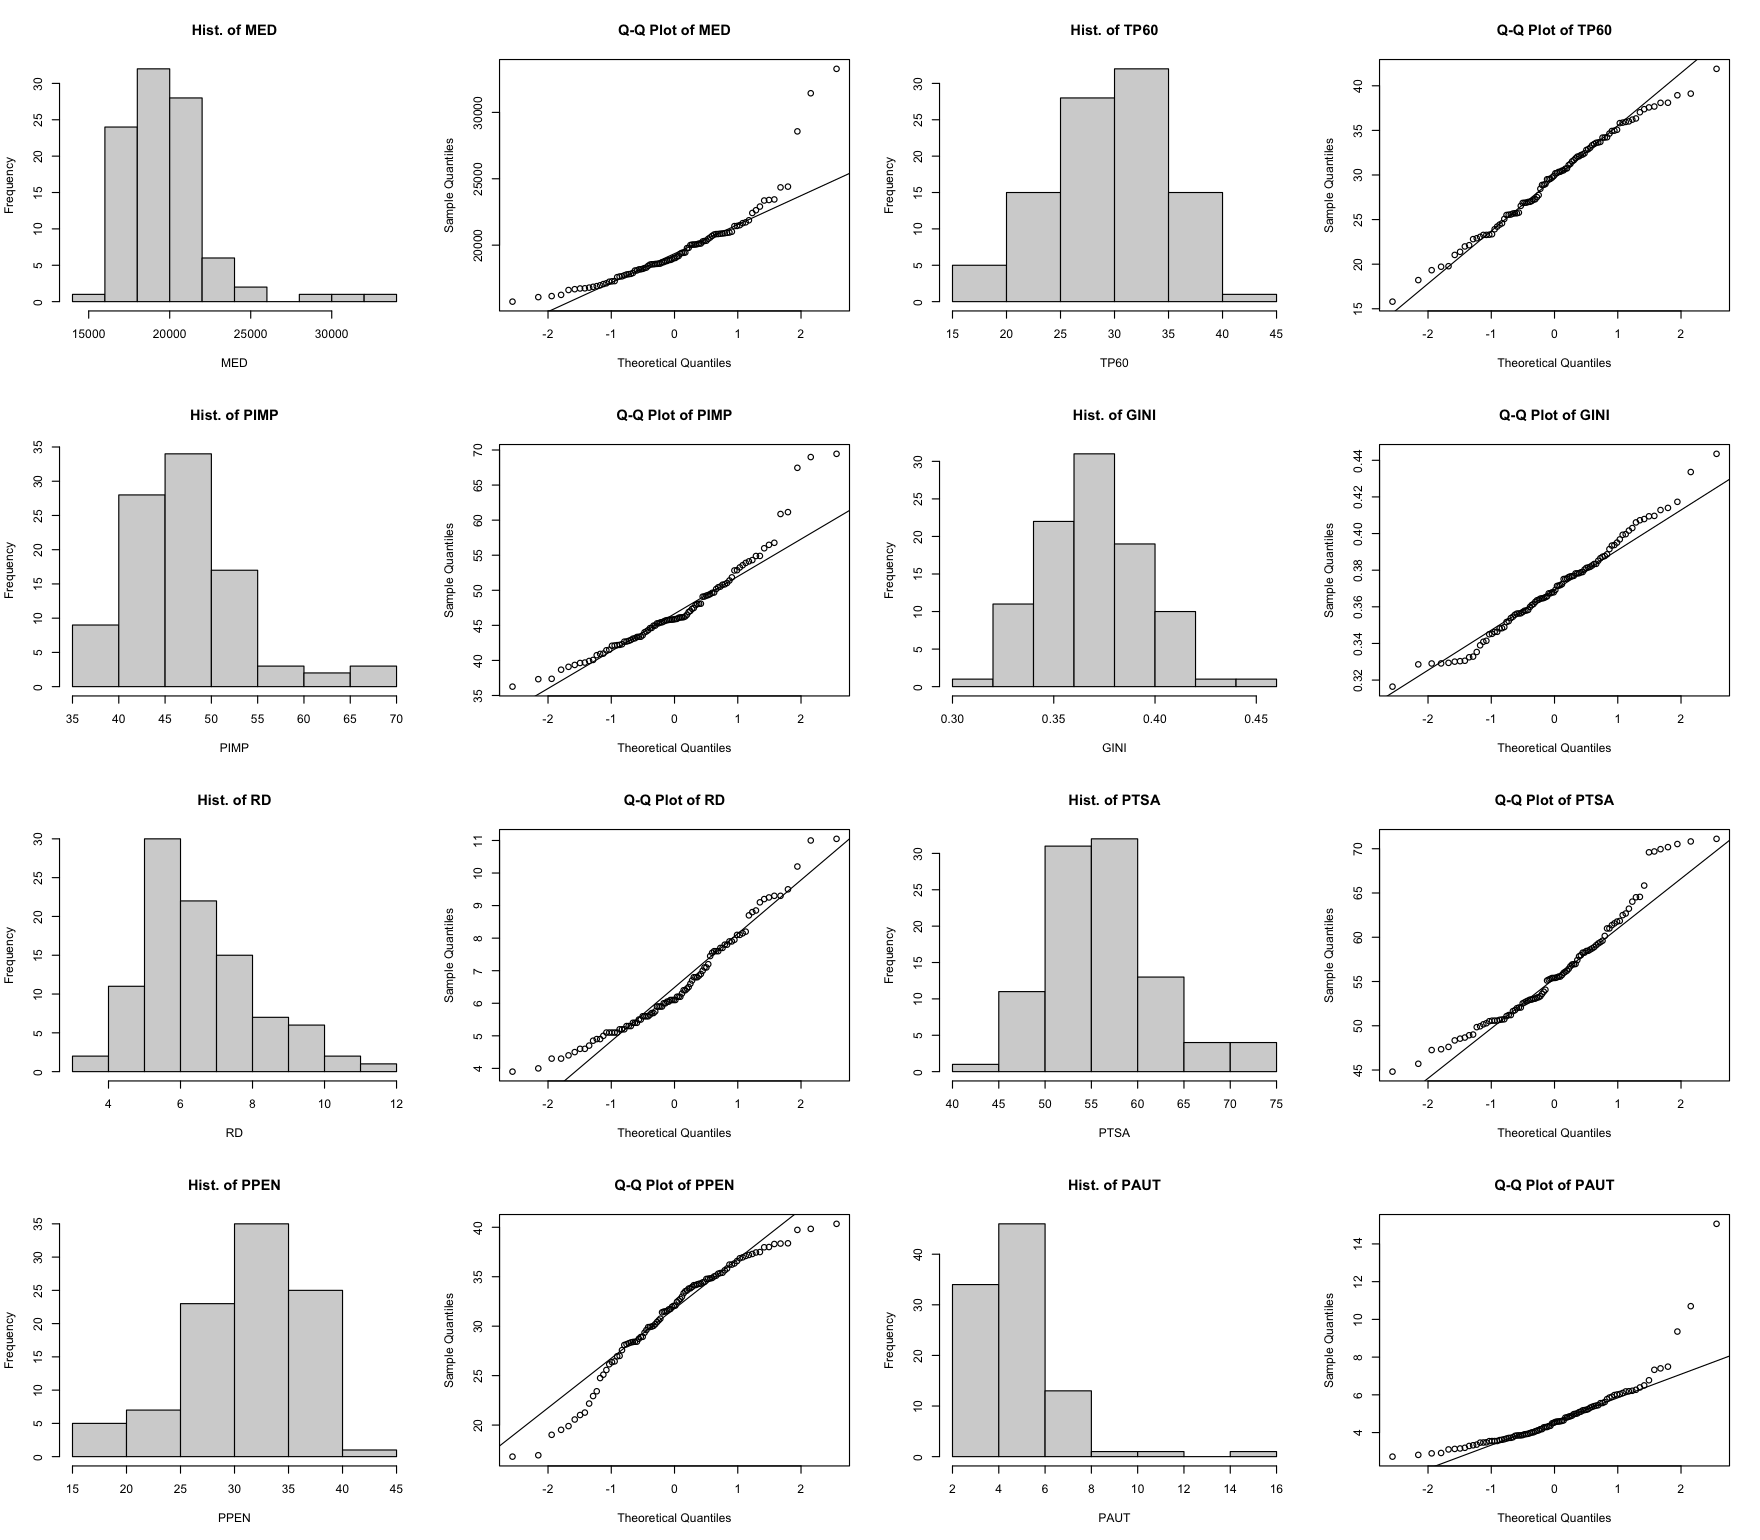

In [20]:
# Visualization of key variables
options(repr.plot.width = 16, repr.plot.height = 14)
a <- c("MED", "TP60", "PIMP", "GINI", "RD", "PTSA", "PPEN", "PAUT")
par(mfrow = c(4, 4))    

# Loop through the variables and create histograms, Q-Q plots, and perform Shapiro-Wilk tests
for (i in 1:length(a)){
  sub = dep_m[a[i]][,1]   
  hist(sub, main = paste("Hist. of", a[i], sep = " "), xlab = a[i])
  qqnorm(sub, main = paste("Q-Q Plot of", a[i], sep = " "))
  qqline(sub)
  if (i == 1) {
    s.t <- shapiro.test(sub)
  } else {
    s.t <- rbind(s.t, shapiro.test(sub))
  }
}
# Reset plotting layout
par(mfrow = c(1, 1))
s.t <- s.t[, 1:2]      
s.t <- cbind(a, s.t)   
s.t

**Interprétation.** 

Seuls TP60 (p = 0,71) et GINI (p = 0,46) suivent une loi normale. Pour les autres variables, p < 0,05 : on rejette la normalité.

### Variable qualitative : répartition des IRIS par région

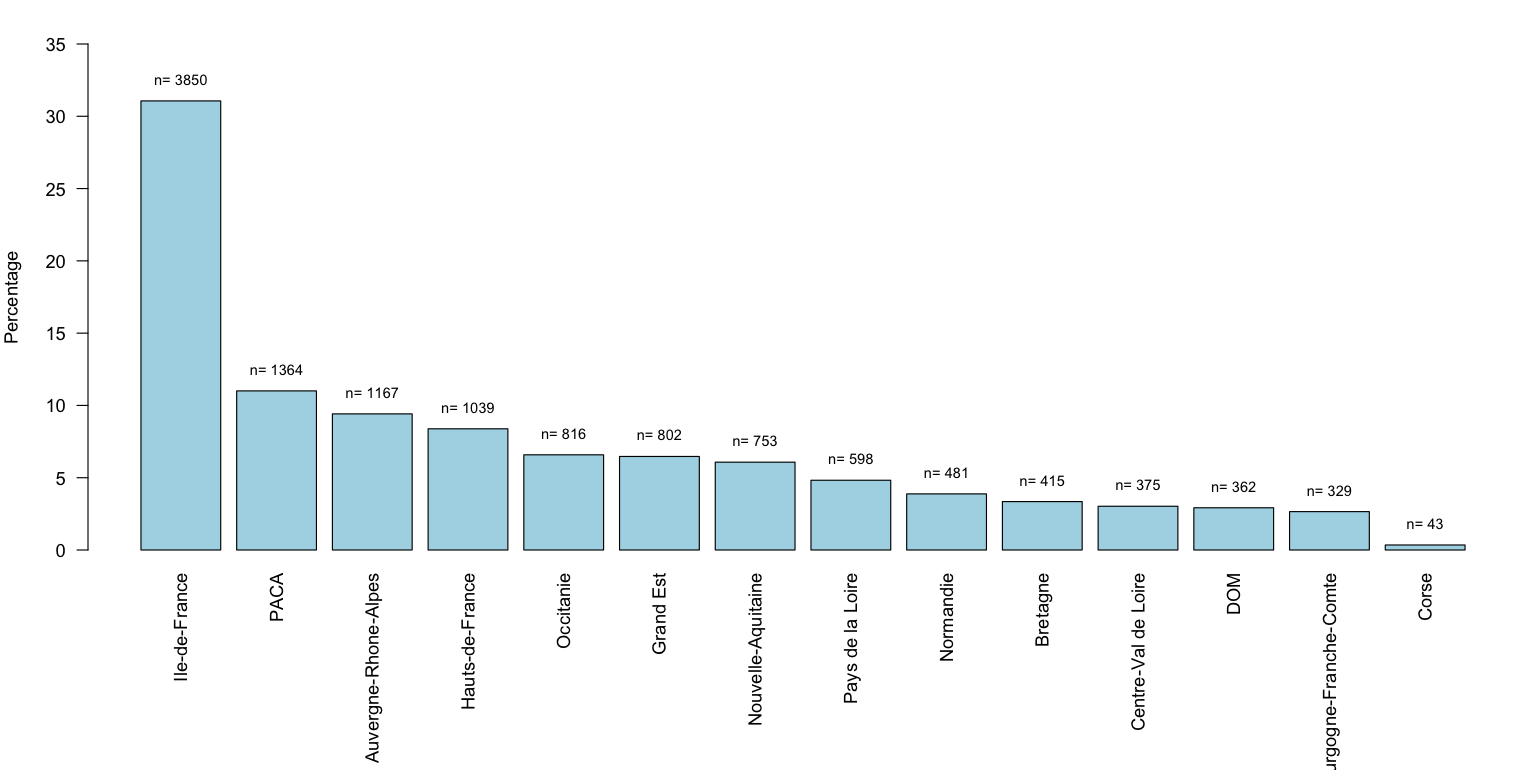

In [22]:
# Visualization of regional distribution
options(repr.plot.width = 14, repr.plot.height = 7)
Region = rename_columns$REGION

# Count the number of IRIS in each region
counts <- sort(table(Region), decreasing = TRUE) 
percentages <- 100 * counts / length(Region)
par(mar = c(10, 4, 2, 1))

# Create a bar plot of the percentages of IRIS in each region
bp <- barplot(percentages, ylab = "Percentage", col = "lightblue", las = 2, ylim = c(0, 35))
text(x = bp, y = percentages + 1.5, paste("n=", counts), cex = 0.8)
par(mar = c(5, 4, 4, 2))

**Interprétation.** 

L'Île-de-France représente 31 % des IRIS : seules les communes de plus de 10 000 habitants sont couvertes, donc les zones urbaines sont surreprésentées.

## Objectif 1 : contrastes entre zones aisées et zones défavorisées

### Revenu médian par département

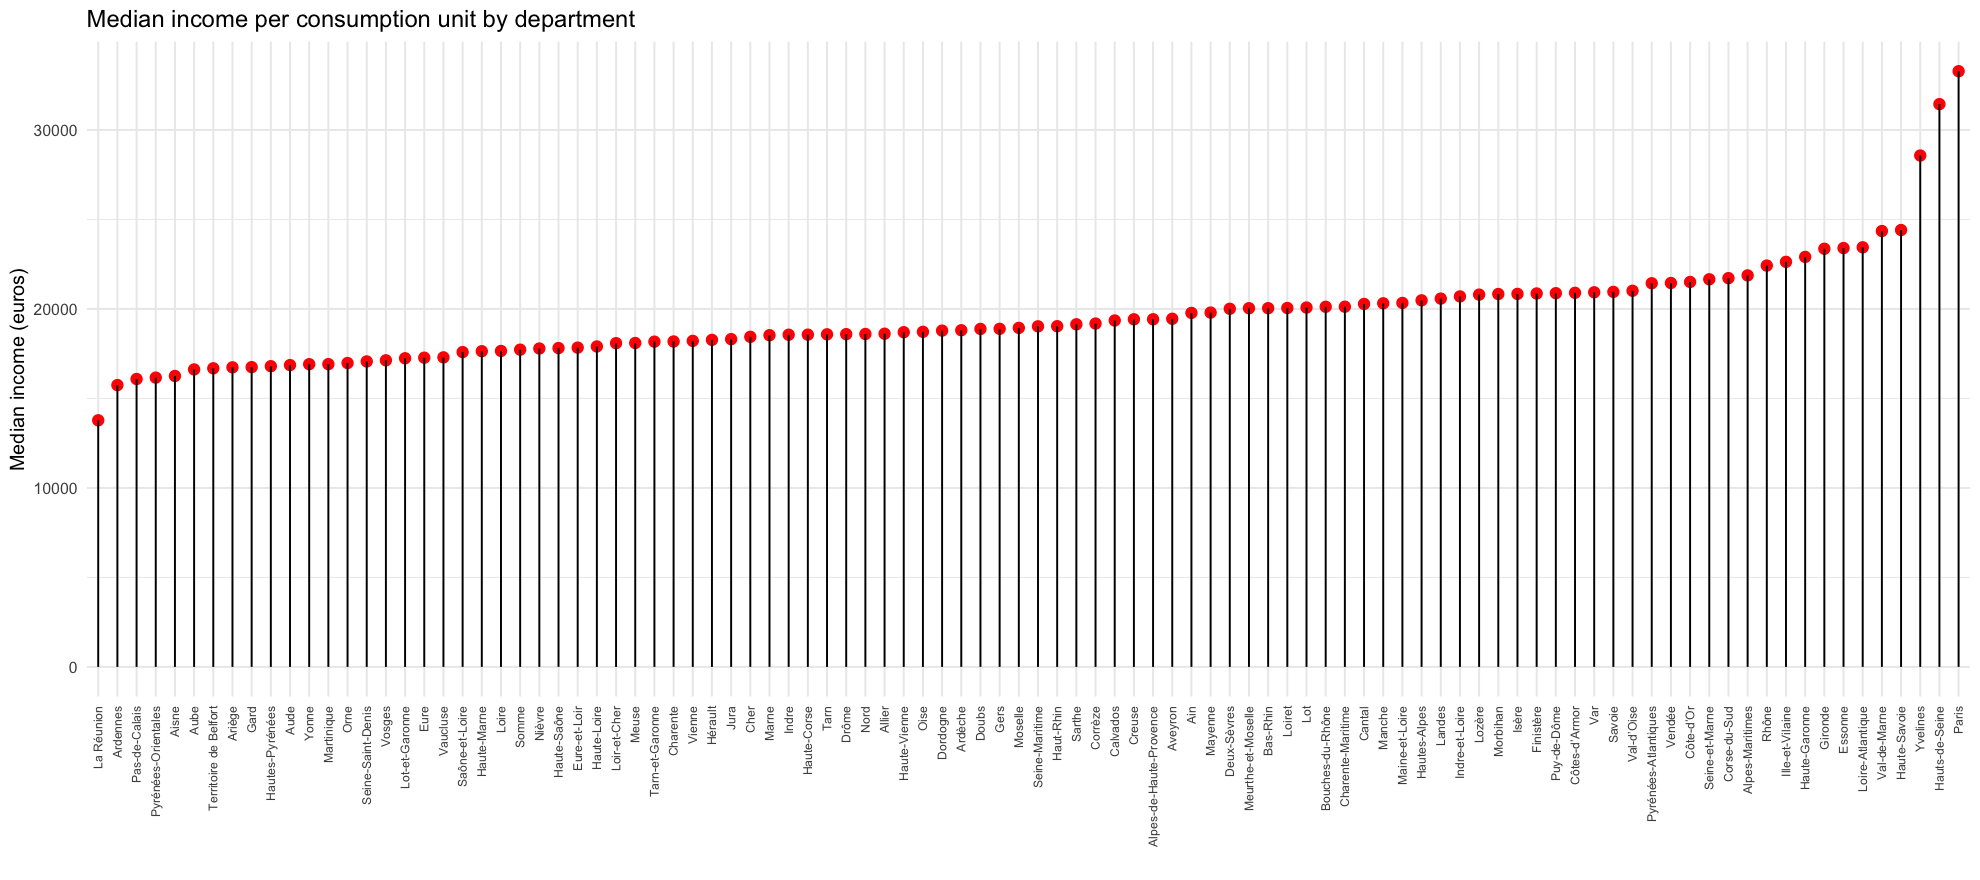

In [23]:
# Visualization of median income by department
options(repr.plot.width = 18, repr.plot.height = 8)

# Create a scatter plot of median income by department with segments from 0 to the median income
ggplot(dep, aes(x = reorder(LIBDEP, MED), y = MED)) + geom_point(size = 3, color = "red") + geom_segment(aes(x = reorder(LIBDEP, MED), xend = reorder(LIBDEP, MED), y = 0, yend = MED)) + labs(title = "Median income per consumption unit by department", x = "", y = "Median income (euros)") + theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size = 8))

In [24]:
# Richest departments
head(dep[order(-dep$MED), c("LIBDEP", "REGION", "MED", "TP60", "GINI")], 10)

# Poorest departments
head(dep[order(dep$MED), c("LIBDEP", "REGION", "MED", "TP60", "GINI")], 10)

,LIBDEP,REGION,MED,TP60,GINI
,<chr>,<fct>,<dbl>,<dbl>,<dbl>
Paris,Paris,Ile-de-France,33280.09,21.03729,0.4435184
Hauts-de-Seine,Hauts-de-Seine,Ile-de-France,31441.64,19.77262,0.3783593
Yvelines,Yvelines,Ile-de-France,28570.27,23.36065,0.3324480
Haute-Savoie,Haute-Savoie,Auvergne-Rhone-Alpes,24407.58,19.32597,0.3482121
Val-de-Marne,Val-de-Marne,Ile-de-France,24350.67,25.67297,0.3564772
Loire-Atlantique,Loire-Atlantique,Pays de la Loire,23442.42,19.71436,0.3328095
Essonne,Essonne,Ile-de-France,23400.56,25.78170,0.3303289
Gironde,Gironde,Nouvelle-Aquitaine,23361.92,21.38406,0.3538182
Haute-Garonne,Haute-Garonne,Occitanie,22905.32,26.88224,0.3803064


,LIBDEP,REGION,MED,TP60,GINI
,<chr>,<fct>,<dbl>,<dbl>,<dbl>
La Réunion,La Réunion,DOM,13777.68,49.91968,0.4952973
Ardennes,Ardennes,Grand Est,15745.00,41.90000,0.4128333
Pas-de-Calais,Pas-de-Calais,Hauts-de-France,16084.43,38.08929,0.3782524
Pyrénées-Orientales,Pyrénées-Orientales,Occitanie,16162.26,37.57586,0.4335968
Aisne,Aisne,Hauts-de-France,16253.73,38.10000,0.4016119
Aube,Aube,Grand Est,16619.36,34.93250,0.3968085
Territoire de Belfort,Territoire de Belfort,Bourgogne-Franche-Comte,16682.22,37.37647,0.3996667
Ariège,Ariège,Occitanie,16736.67,31.52000,0.3873333
Gard,Gard,Occitanie,16748.83,39.12128,0.4060777


### Cartes de chaleur géographique

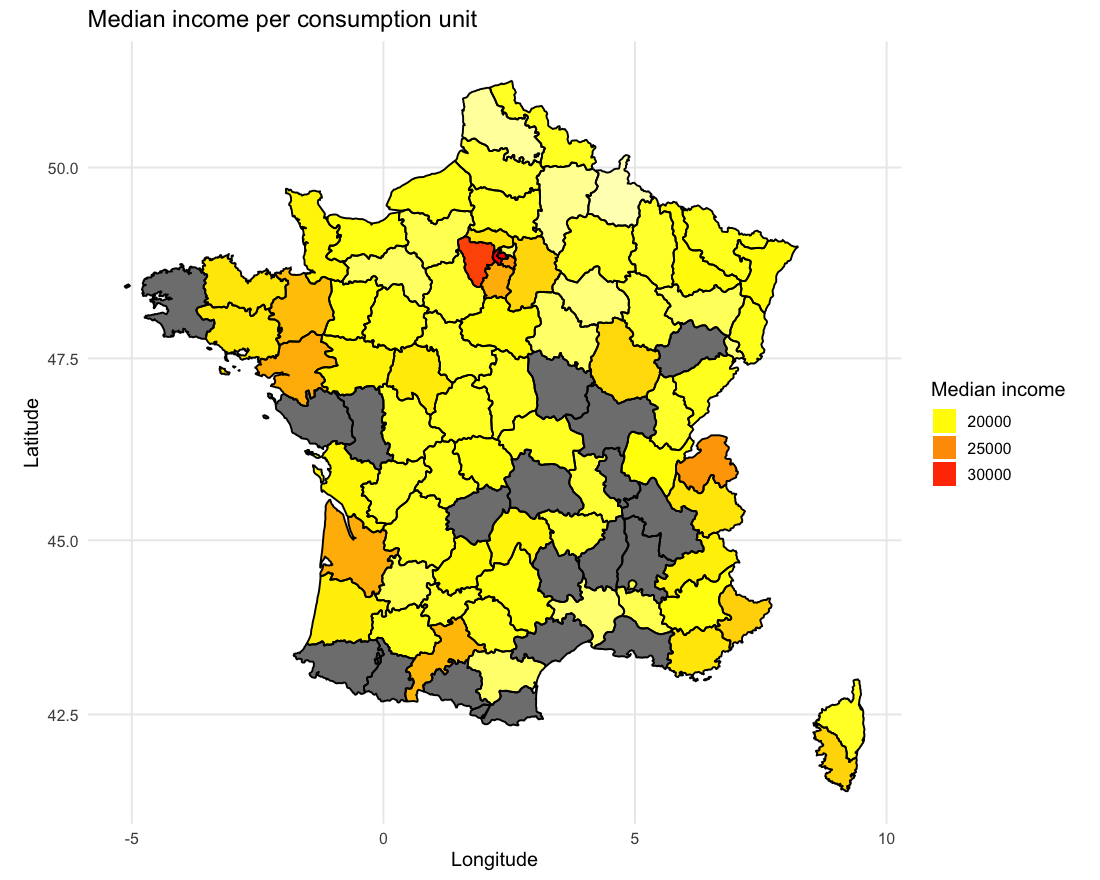

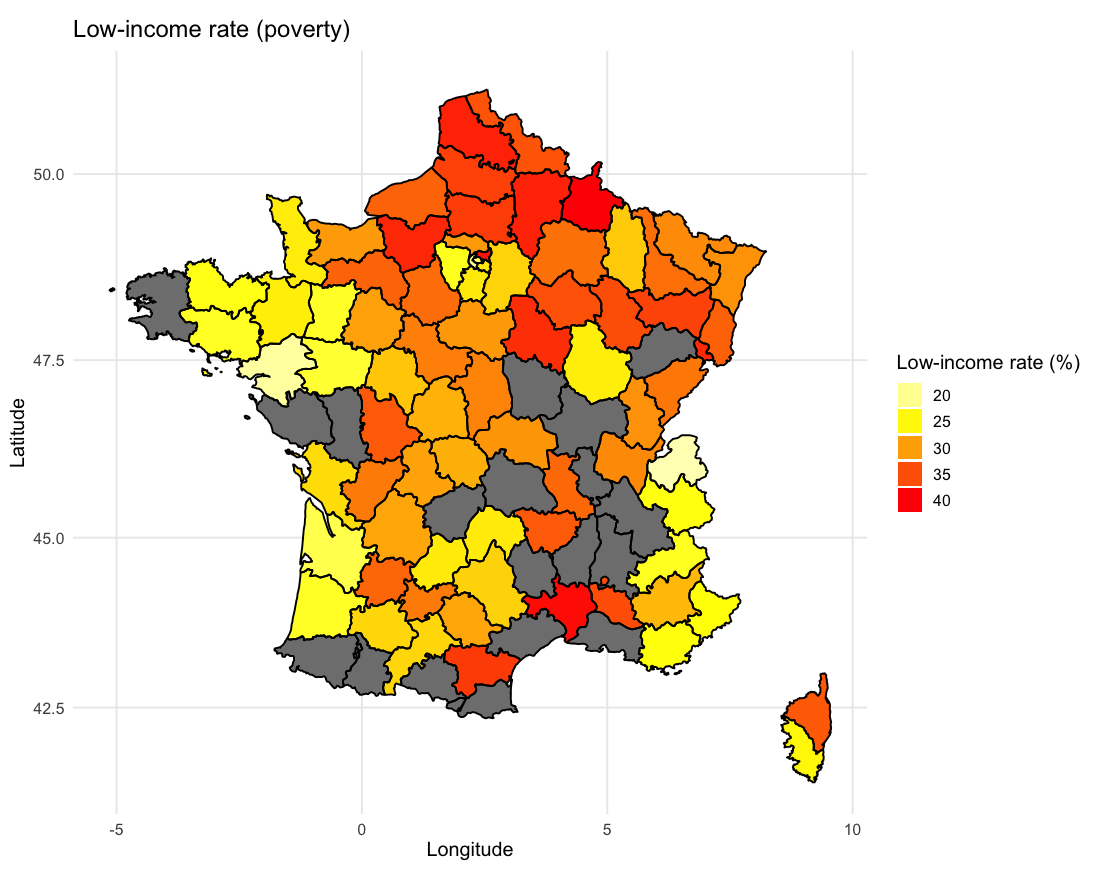

In [26]:
# Department names as written in map_data("france")
dep_m$region <- iconv(dep_m$LIBDEP, from = "UTF-8", to = "ASCII//TRANSLIT")
dep_m$region[dep_m$DEP == "21"] <- "Cote-Dor"
dep_m$region[dep_m$DEP == "22"] <- "Cotes-Darmor"
dep_m$region[dep_m$DEP == "2A"] <- "Corse du Sud"
dep_m$region[dep_m$DEP == "95"] <- "Val-Doise"

# Merge the map with our data
france <- map_data("france")
map <- merge(france, dep_m, by = "region", all.x = T)
map <- map[order(map$order), ]

options(repr.plot.width = 10, repr.plot.height = 8)

# Map of the median income
ggplot(map, aes(x = long, y = lat, group = group)) + geom_polygon(aes(fill = MED)) + geom_path() + scale_fill_gradientn(colours = rev(heat.colors(10))) + coord_map() + labs(title = "Median income per consumption unit", x = "Longitude", y = "Latitude") + guides(fill = guide_legend(title = "Median income"))

# Map of the low-income rate
ggplot(map, aes(x = long, y = lat, group = group)) + geom_polygon(aes(fill = TP60)) + geom_path() + scale_fill_gradientn(colours = rev(heat.colors(10))) + coord_map() + labs(title = "Low-income rate (poverty)", x = "Longitude", y = "Latitude") + guides(fill = guide_legend(title = "Low-income rate (%)"))

### Boîtes à moustaches par région

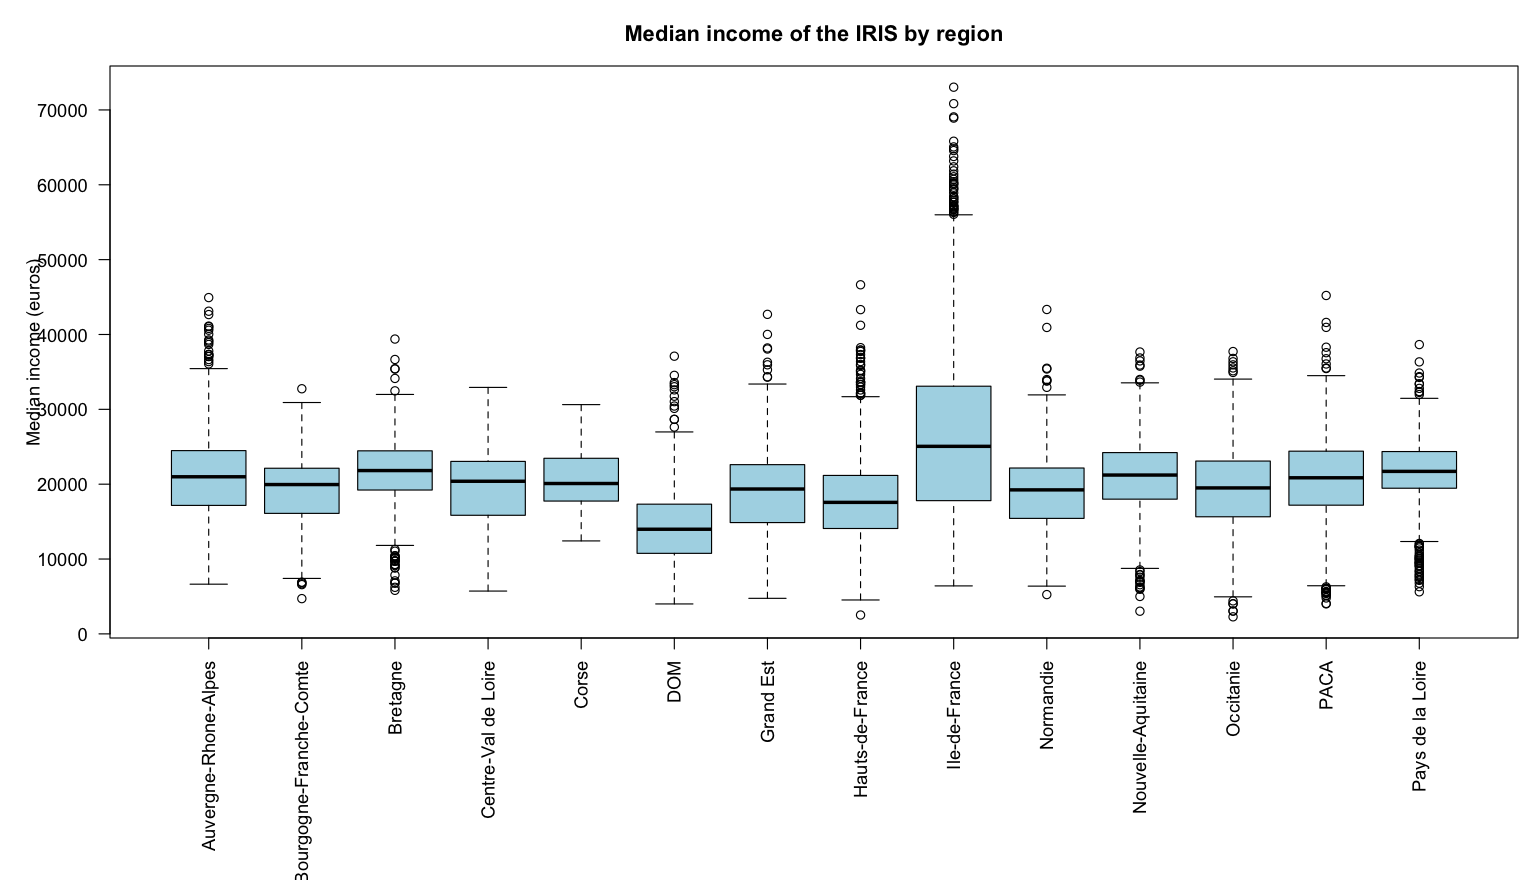

In [27]:
# Boxplot of the median income of the IRIS by region
options(repr.plot.width = 14, repr.plot.height = 8)
par(mar = c(11, 5, 3, 1))

# Create a boxplot of median income by region
boxplot(rename_columns$MED ~ rename_columns$REGION, xlab = "", ylab = "Median income (euros)", las = 2, col = "lightblue", main = "Median income of the IRIS by region")
par(mar = c(5, 4, 4, 2))

**Interprétation.**
- Départements les plus riches : Paris (33 280 €), Hauts-de-Seine (31 440 €), Yvelines.
- Départements les plus pauvres : La Réunion (13 780 €), Ardennes, Pas-de-Calais.
- La carte de la pauvreté est presque l'inverse de celle du revenu. La pauvreté est forte dans le Nord, le Nord-Est et sur le pourtour méditerranéen.
- L'Île-de-France a la médiane la plus haute, mais aussi l'écart interquartile le plus grand. C'est la région la plus hétérogène.

## Objectif 2 : structure du revenu
Barres empilées, et carte de la part des retraites.

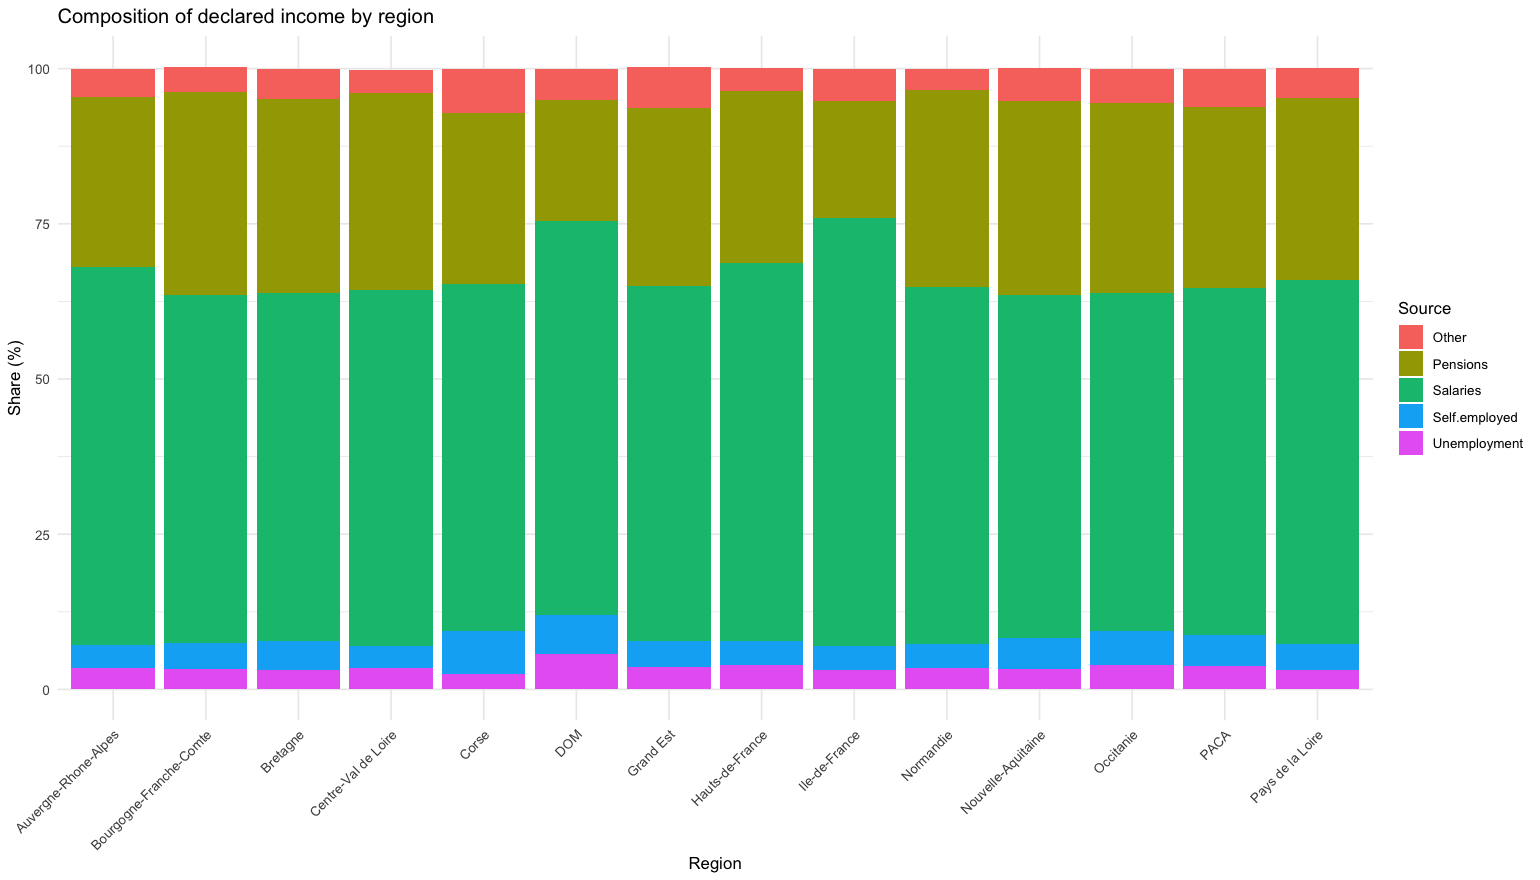

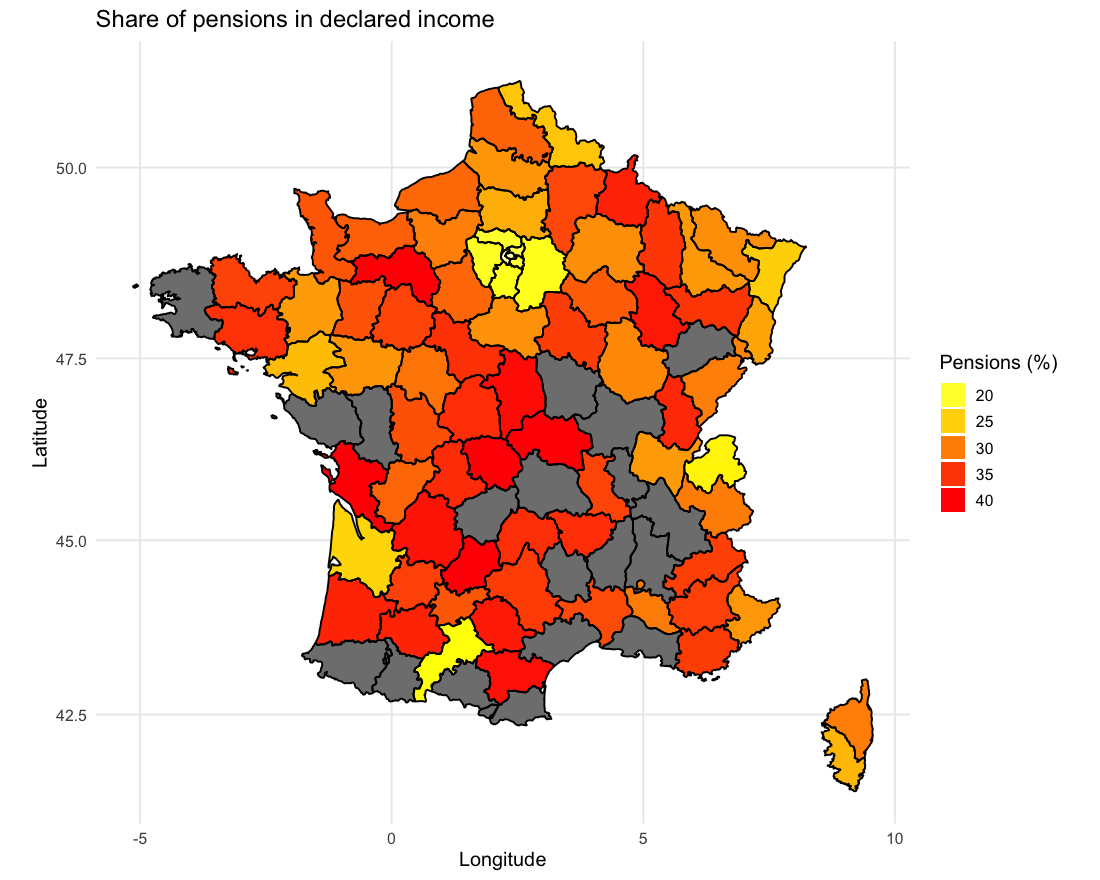

In [28]:
# Mean share of each income source by region
sources <- c("PTSA", "PCHO", "PBEN", "PPEN", "PAUT")
struct_reg <- aggregate(rename_columns[, sources], by = list(Region = rename_columns$REGION), FUN = mean, na.rm = TRUE)
names(struct_reg) <- c("Region", "Salaries", "Unemployment", "Self.employed", "Pensions", "Other")

# Convert the data to long format and plot the stacked bars
struct_reg_long <- pivot_longer(struct_reg, cols = -Region, names_to = "Source", values_to = "Share")
options(repr.plot.width = 14, repr.plot.height = 8)
ggplot(struct_reg_long, aes(x = Region, y = Share, fill = Source)) + geom_bar(stat = "identity") + theme_minimal() + labs(title = "Composition of declared income by region", x = "Region", y = "Share (%)") + theme(axis.text.x = element_text(angle = 45, hjust = 1))

# Map of the share of pensions
options(repr.plot.width = 10, repr.plot.height = 8)
ggplot(map, aes(x = long, y = lat, group = group)) + geom_polygon(aes(fill = PPEN)) + geom_path() + scale_fill_gradientn(colours = rev(heat.colors(10))) + coord_map() + labs(title = "Share of pensions in declared income", x = "Longitude", y = "Latitude") + guides(fill = guide_legend(title = "Pensions (%)"))

**Interprétation.** 

L'Île-de-France et les métropoles vivent surtout des salaires (69 % en Île-de-France). Le centre et l'ouest de la France vivent davantage des retraites (jusqu'à 40 % dans l'Allier).

## Objectif 3 : lien entre pauvreté et inégalités
### Matrice de corrélations (départements)

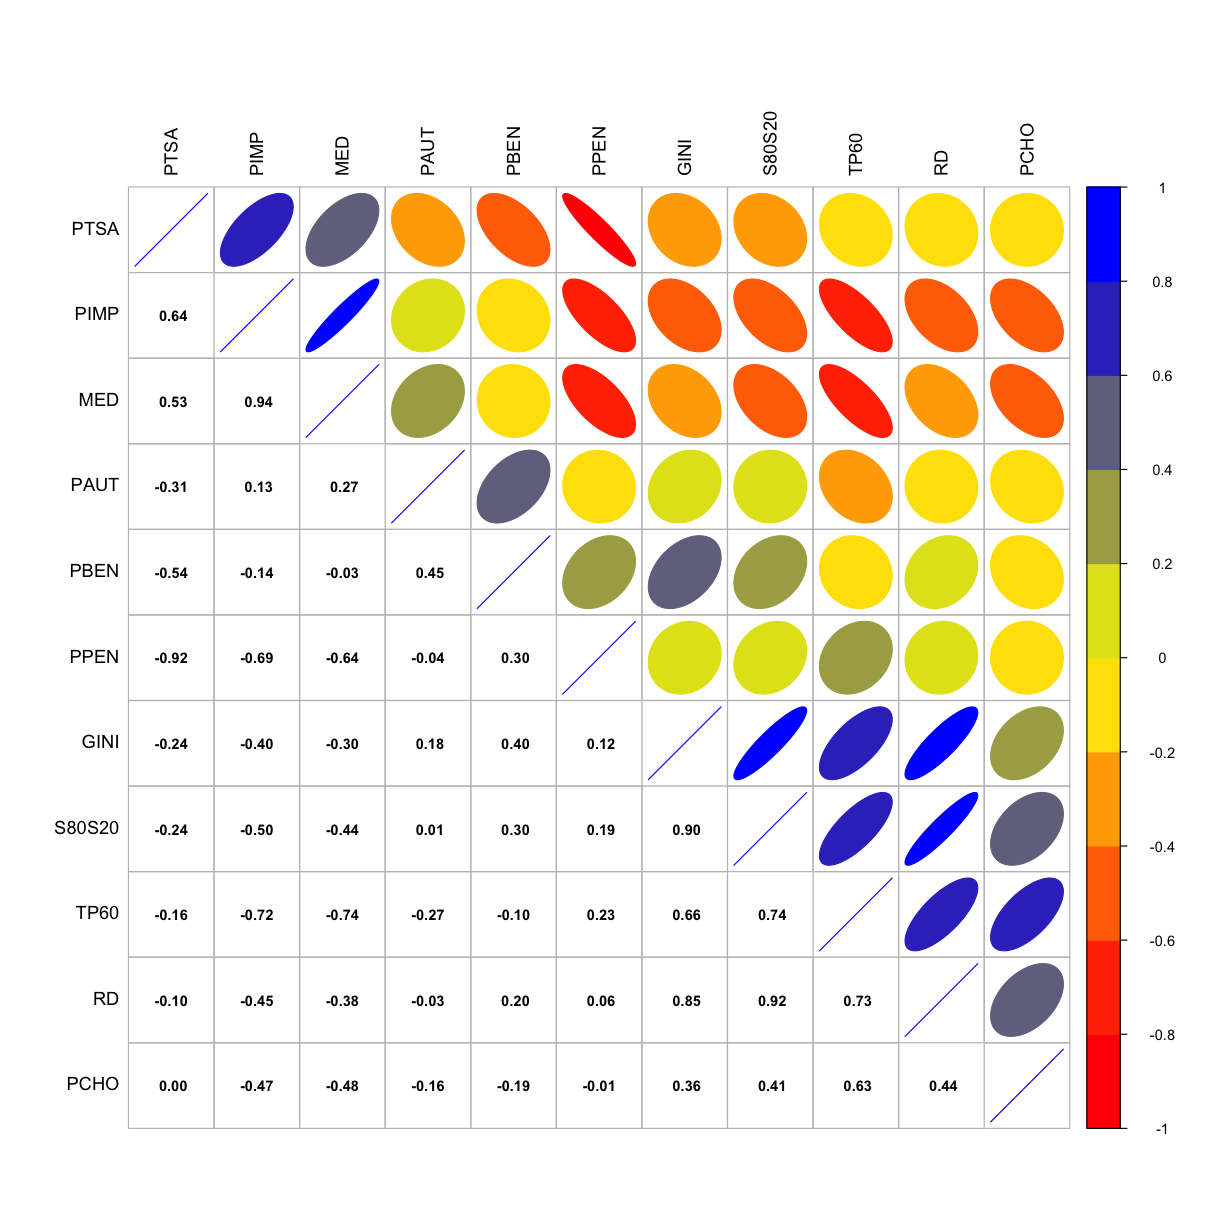

In [29]:
# Correlation matrix of the department-level variables
st <- dep_m[, c("MED", "TP60", "PIMP", "GINI", "RD", "S80S20", "PTSA", "PCHO", "PBEN", "PPEN", "PAUT")]
corMatrix <- cor(as.matrix(st))

# Plot the correlation matrix
options(repr.plot.width = 11, repr.plot.height = 11)
col <- colorRampPalette(c("red", "yellow", "blue"))
corrplot.mixed(corMatrix, order = "AOE", lower = "number", lower.col = "black", number.cex = .8, upper = "ellipse", upper.col = col(10), diag = "u", tl.pos = "lt", tl.col = "black")

**Interprétation.** 

Le taux de bas revenus est corrélé négativement au revenu médian (r = −0,74) et positivement aux inégalités : Gini r = 0,66, D9/D1 r = 0,73.

### Pauvreté vs inégalités

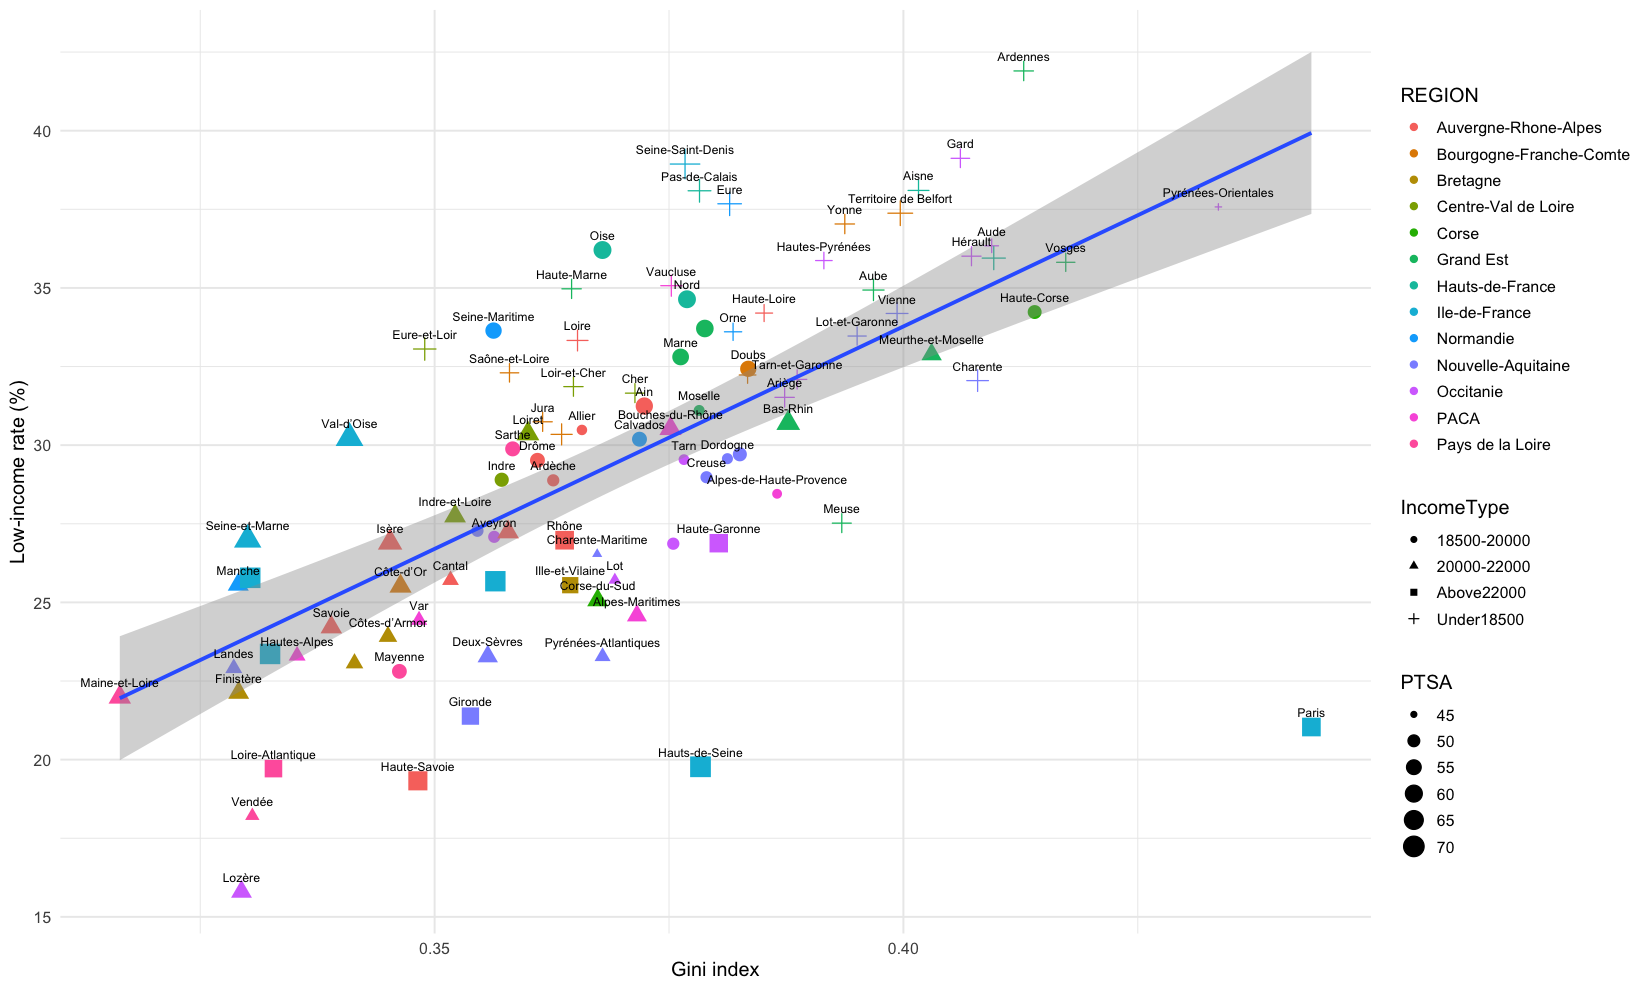

In [31]:
# Income classes, as IncomeType in visualization_state.r
dep_income <- dep_m %>% mutate(IncomeType = factor(ifelse(MED < 18500, "Under18500", ifelse(MED < 20000, "18500-20000", ifelse(MED < 22000, "20000-22000", "Above22000")))))
options(repr.plot.width = 15, repr.plot.height = 9)

# Create a scatter plot of Gini index vs low-income rate
ggplot(dep_income, aes(x = GINI, y = TP60)) + geom_point(aes(shape = IncomeType, color = REGION, size = PTSA)) + geom_smooth(method = 'lm', formula = y ~ x) + geom_text(aes(label = LIBDEP), size = 2.8, vjust = -1.2, check_overlap = TRUE) + labs(x = "Gini index", y = "Low-income rate (%)")